# SmartBike AI: Bike Rental Demand Prediction

**Predictive Analytics Project**

---

### Project Overview
Bike-sharing systems provide a clean and affordable urban transportation option. However, managing bike availability is challenging because demand changes across hours, days, and weather conditions.

This project explores bike rental data, examines demand patterns, compares regression and classification models, and identifies suitable models for prediction.

The project includes:
1. **Data Preparation and Exploratory Data Analysis:** Inspect the dataset, check missing values and duplicates, inspect outliers, and visualize demand patterns.
2. **Regression Analysis:** Predict hourly bike rental counts using Multiple Linear Regression, Decision Tree Regression, and Polynomial Regression (degree 2).
3. **Classification Analysis:** Predict whether an hour has High Demand or Normal Demand using K-Nearest Neighbors, Decision Tree Classifier, and Gaussian Naive Bayes.

### Dataset Source
- **Official Dataset:** UCI Machine Learning Repository — Bike Sharing Dataset (`hour.csv`)
- **URL:** https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset


## Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier , DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

## Load and Inspect the Dataset

In [3]:
df = pd.read_csv("hour.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (17379, 17)

Column Names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [6]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


## Data Cleaning and Outlier Detection

In [7]:
print("Missing values per column:")
df.isnull().sum()

Missing values per column:


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
duplicates = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicates)


Number of duplicate rows: 0


Q1 (25th percentile): 40.0
Q3 (75th percentile): 281.0
IQR (Interquartile Range): 241.0
Lower Bound: -321.5
Upper Bound: 642.5
Number of outliers found in cnt: 505


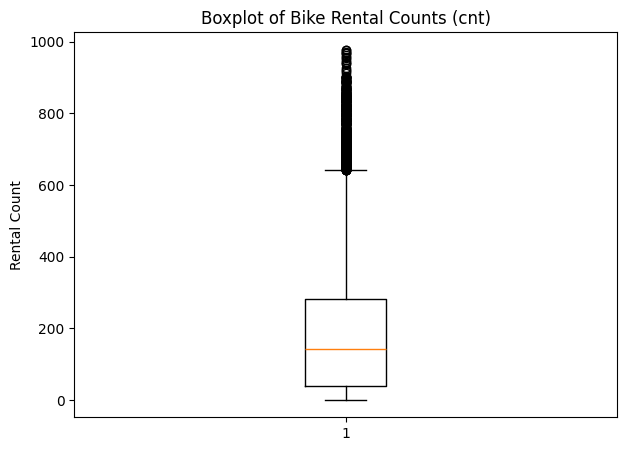

In [9]:
q1 = df["cnt"].quantile(0.25)
q3 = df["cnt"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("Q1 (25th percentile):", q1)
print("Q3 (75th percentile):", q3)
print("IQR (Interquartile Range):", iqr)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
outliers = ((df["cnt"] < lower_bound) | (df["cnt"] > upper_bound)).sum()
print("Number of outliers found in cnt:", outliers)
plt.figure(figsize=(7, 5))
plt.boxplot(df["cnt"])
plt.title("Boxplot of Bike Rental Counts (cnt)")
plt.ylabel("Rental Count")
plt.show()

**Decision on Outliers:**  
The boxplot reveals points exceeding 642.5 rentals per hour as statistical outliers. However, these points correspond to peak commuter rush hours (e.g., 8:00 AM and 5:00 PM on pleasant weekdays during summer and fall). They are legitimate, high-volume capacity events that the bike-sharing business must prepare for, rather than data errors. Therefore, we **retain** these records so our models can learn peak-demand behavior.


## Exploratory Data Analysis (EDA)

### Bike Rentals by Hour of the Day

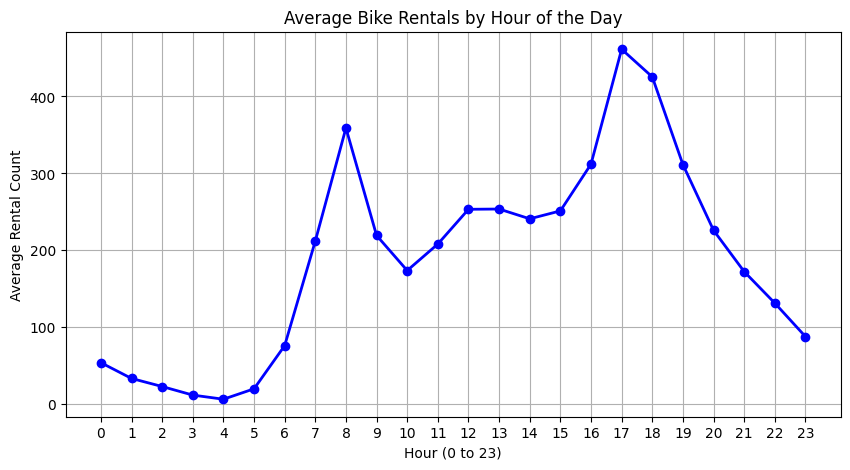

In [10]:
# Average rentals by hour
hourly_avg = df.groupby('hr')['cnt'].mean()
plt.figure(figsize=(10, 5))
hourly_avg.plot(kind='line', marker='o', color='blue', linewidth=2)
plt.title("Average Bike Rentals by Hour of the Day")
plt.xlabel("Hour (0 to 23)")
plt.ylabel("Average Rental Count")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

**Explanation:**  
The hourly line plot clearly shows two prominent commuter peaks at **8:00 AM** and **5:00 PM - 6:00 PM**. In contrast, demand drops to near zero during late night and early morning hours (12:00 AM to 5:00 AM).


### Bike Rentals by Month and Season

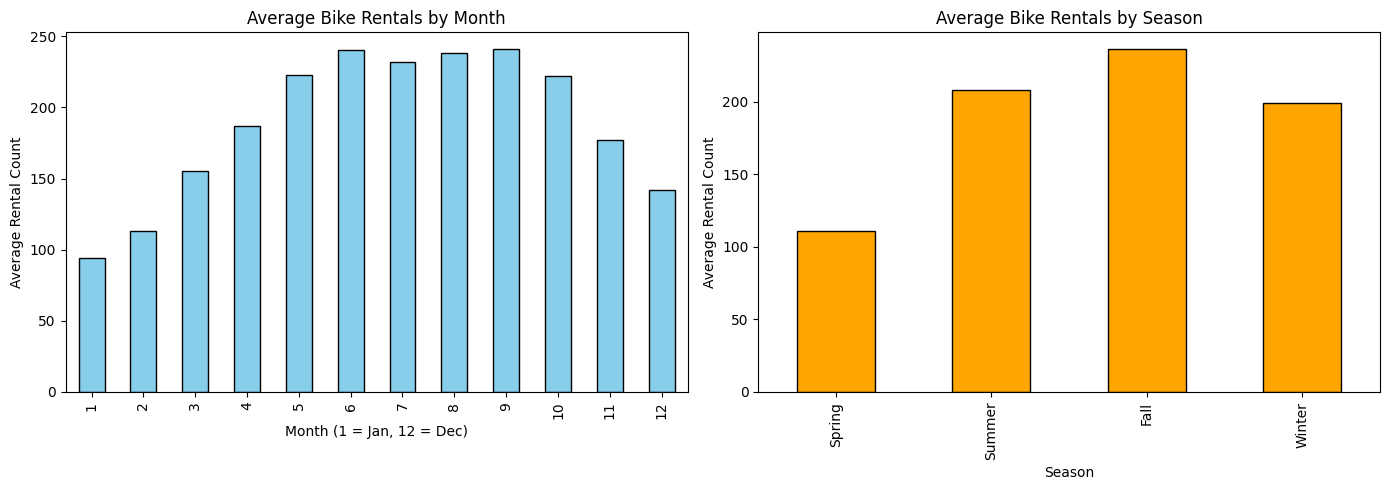

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
monthly_avg = df.groupby('mnth')['cnt'].mean()
monthly_avg.plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title("Average Bike Rentals by Month")
axes[0].set_xlabel("Month (1 = Jan, 12 = Dec)")
axes[0].set_ylabel("Average Rental Count")

season_names = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
season_avg = df.groupby('season')['cnt'].mean()
season_avg.index = season_avg.index.map(season_names)
season_avg.plot(kind='bar', ax=axes[1], color='orange', edgecolor='black')
axes[1].set_title("Average Bike Rentals by Season")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Average Rental Count")
plt.tight_layout()
plt.show()


**Explanation:**  
Demand is highest during Summer and Fall (months 5 to 10), while winter months (January and February) experience the lowest demand due to cold temperatures.


### Bike Rentals by Weather Situation

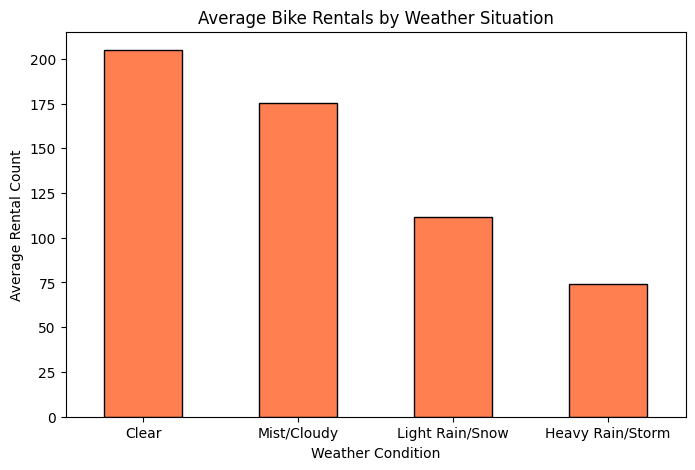

In [12]:
weather_labels = {
    1: 'Clear',
    2: 'Mist/Cloudy',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Storm'
}
weather_avg = df.groupby('weathersit')['cnt'].mean()
weather_avg.index = weather_avg.index.map(weather_labels)
plt.figure(figsize=(8, 5))
weather_avg.plot(kind='bar', color='coral', edgecolor='black')
plt.title("Average Bike Rentals by Weather Situation")
plt.xlabel("Weather Condition")
plt.ylabel("Average Rental Count")
plt.xticks(rotation=0)
plt.show()

**Explanation:**  
Clear weather has the highest rental average (over 205 bikes/hr). Rainy and snowy conditions drop demand significantly, and severe storms reduce demand to a minimum.


### Distribution of Rental Counts

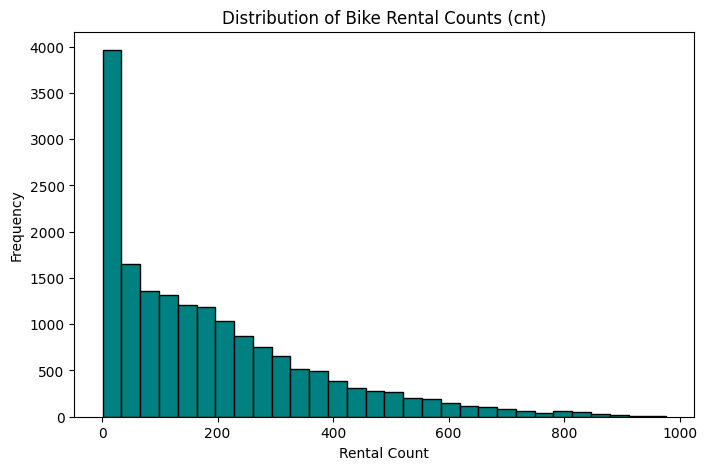

In [13]:
plt.figure(figsize=(8, 5))
plt.hist(df['cnt'], bins=30, color='teal', edgecolor='black')
plt.title("Distribution of Bike Rental Counts (cnt)")
plt.xlabel("Rental Count")
plt.ylabel("Frequency")
plt.show()

**Explanation:**  
The distribution of `cnt` is right-skewed. Most hours experience modest rental counts (under 200), with a long tail representing heavy rush hours.


### Correlation Heatmap

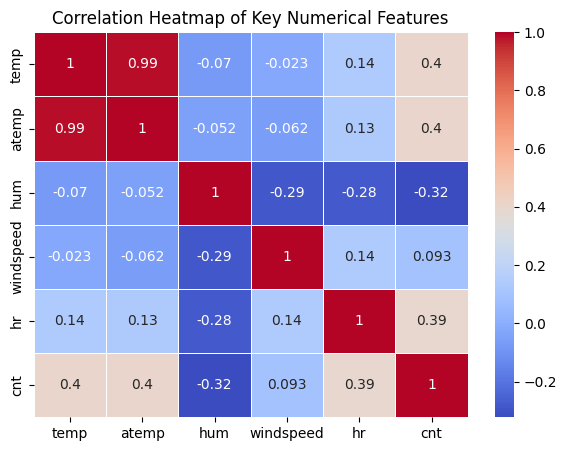

In [14]:
numeric_cols = ['temp','atemp','hum','windspeed','hr','cnt']
corr = df[numeric_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm',linewidths=0.5)
plt.title("Correlation Heatmap of Key Numerical Features")
plt.show()

**Explanation:**  
- `temp` and `atemp` have positive correlation ($+0.40$) with `cnt` (warmer weather increases bike usage).
- `hum` (humidity) has negative correlation ($-0.32$) with `cnt` (high humidity / wet conditions discourage cycling).

---
## Regression Models

In [15]:
features = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit','temp','atemp','hum','windspeed']
x = df[features]
y = df['cnt']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

### Multiple Linear Regression

This model uses the selected calendar, time, and weather features to predict hourly bike rentals.


In [16]:
m_model = LinearRegression()
m_model.fit(x_train, y_train)
m_ypred = m_model.predict(x_test)
m_mae = mean_absolute_error(y_test, m_ypred)
m_mse = mean_squared_error(y_test, m_ypred)
m_rmse = np.sqrt(m_mse)
m_r2 = r2_score(y_test, m_ypred)
print("Linear Regression Results:")
print("MAE :", m_mae)
print("MSE :", m_mse)
print("RMSE:", m_rmse)
print("R2  :", m_r2)

Linear Regression Results:
MAE : 104.8033508955442
MSE : 19379.828367651717
RMSE: 139.21145199893476
R2  : 0.38798115831391344


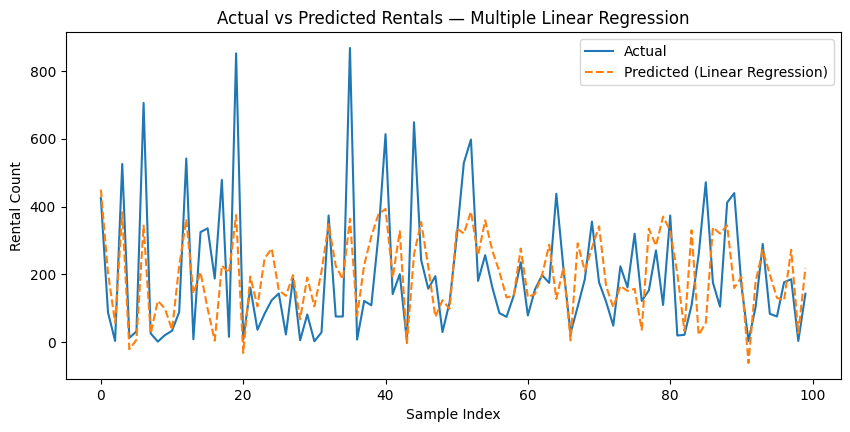

In [28]:
# Plot actual versus predicted values for Linear Regression
plt.figure(figsize=(10, 4.5))
sample_indices = range(100)
plt.plot(sample_indices, y_test.iloc[:100].values, label='Actual', linewidth=1.5)
plt.plot(sample_indices, m_ypred[:100], label='Predicted (Linear Regression)', linestyle='--', linewidth=1.5)
plt.title("Actual vs Predicted Rentals — Multiple Linear Regression")
plt.xlabel("Sample Index")
plt.ylabel("Rental Count")
plt.legend()
plt.show()

### Decision Tree Regression

I used multiple features to predict hourly bike rentals. The model makes decisions by splitting the data into smaller groups and learning patterns.

In [18]:
model_tree = DecisionTreeRegressor(max_depth=6, random_state=42)
model_tree.fit(x_train, y_train)
d_ypred = model_tree.predict(x_test)
d_mae = mean_absolute_error(y_test, d_ypred)
d_mse = mean_squared_error(y_test, d_ypred)
d_rmse = np.sqrt(d_mse)
d_r2 = r2_score(y_test, d_ypred)
print("Decision Tree Regression Results:")
print("MAE:", d_mae)
print("MSE:", d_mse)
print("RMSE:", d_rmse)
print("R2 Score:", d_r2)

Decision Tree Regression Results:
MAE: 64.05086160718906
MSE: 9804.63990278452
RMSE: 99.01838164090807
R2 Score: 0.690367518090746


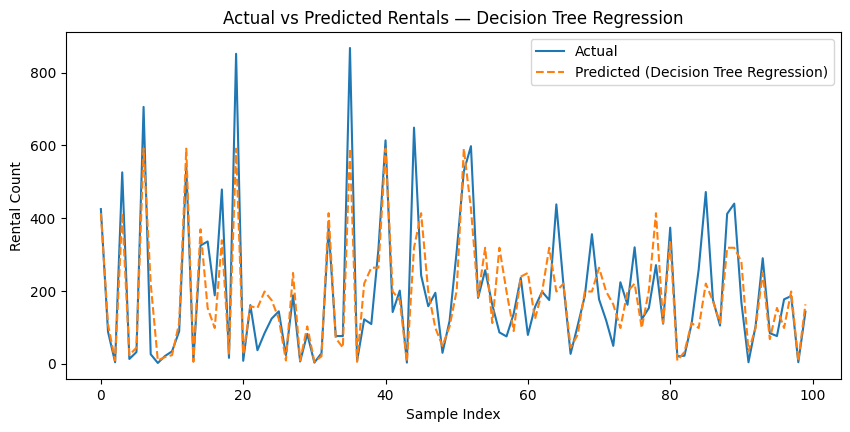

In [19]:
plt.figure(figsize=(10, 4.5))
sample_indices = range(100)
plt.plot(sample_indices, y_test.iloc[:100].values,label="Actual", linewidth=1.5)
plt.plot(sample_indices, d_ypred[:100], label="Predicted (Decision Tree Regression)",linestyle="--", linewidth=1.5)
plt.title("Actual vs Predicted Rentals — Decision Tree Regression")
plt.xlabel("Sample Index")
plt.ylabel("Rental Count")
plt.legend()
plt.show()

### Polynomial Regression (Degree 2)

In [20]:
poly = PolynomialFeatures(degree=2)
x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)
model_poly = LinearRegression()
model_poly.fit(x_train_poly, y_train)
p_ypred = model_poly.predict(x_test_poly)
p_mae = mean_absolute_error(y_test, p_ypred)
p_mse = mean_squared_error(y_test, p_ypred)
p_rmse = np.sqrt(p_mse)
p_r2 = r2_score(y_test, p_ypred)
print("Polynomial Regression (Degree 2) Results:")
print("MAE :", p_mae)
print("MSE :", p_mse)
print("RMSE:", p_rmse)
print("R2  :", p_r2)

Polynomial Regression (Degree 2) Results:
MAE : 91.2534241143564
MSE : 14503.477453270583
RMSE: 120.43038426107667
R2  : 0.541977291904856


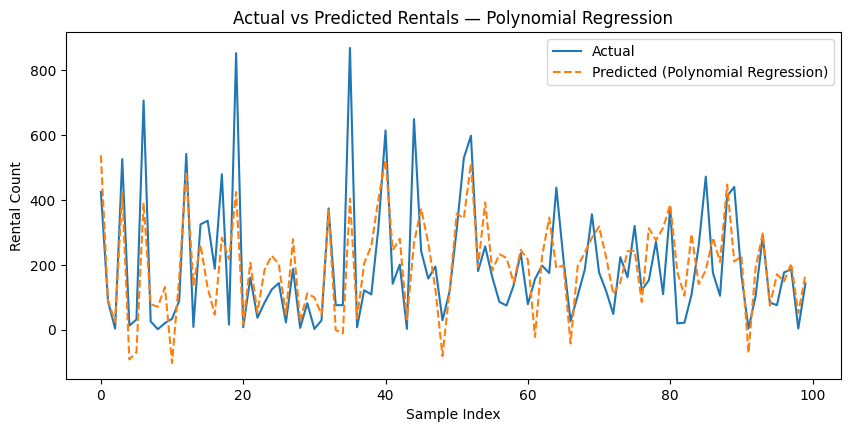

In [29]:
plt.figure(figsize=(10, 4.5))
plt.plot(sample_indices, y_test.iloc[:100].values, label='Actual', linewidth=1.5)
plt.plot(sample_indices, p_ypred[:100], label='Predicted (Polynomial Regression)', linestyle='--', linewidth=1.5)
plt.title("Actual vs Predicted Rentals — Polynomial Regression")
plt.xlabel("Sample Index")
plt.ylabel("Rental Count")
plt.legend()
plt.show()

### Regression Model Comparison

I compared Multiple Linear Regression, Decision Tree Regression, and Polynomial Regression using RMSE and R². A lower RMSE indicates smaller prediction errors.

Regression Model Comparison:


,Model,RMSE,R2
0,Multiple Linear Regression,139.2115,0.3880
1,Decision Tree Regression,99.0184,0.6904
2,Polynomial Regression,120.4304,0.5420


Best Regression Model: Decision Tree Regression


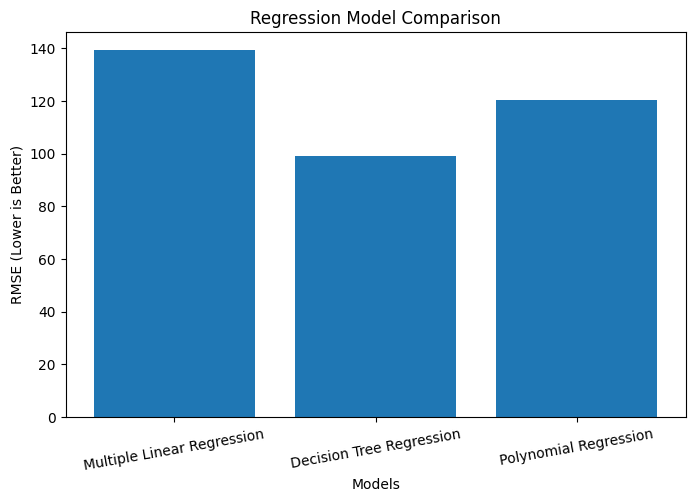

In [22]:
reg_summary = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Decision Tree Regression',
        'Polynomial Regression'
    ],
    'RMSE': [m_rmse, d_rmse, p_rmse],
    'R2': [m_r2, d_r2, p_r2]
})
print("Regression Model Comparison:")
display(reg_summary.round(4))
best_regression_name = reg_summary.loc[
    reg_summary['RMSE'].idxmin(), 'Model'
]
print("Best Regression Model:", best_regression_name)
plt.figure(figsize=(8, 5))
plt.bar(reg_summary['Model'], reg_summary['RMSE'])
plt.title("Regression Model Comparison")
plt.xlabel("Models")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=10)
plt.show()

**Regression Conclusion**

The model with the lowest test RMSE performs best on this test split. Compare the three regression models before choosing the model for prediction.


---
## Classification Models

In [23]:
y_train_clf = pd.qcut(
    y_train,
    q=2,
    labels=[0, 1]
)
bins = pd.qcut(y_train, q=2, retbins=True)[1]
y_test_clf = pd.cut(
    y_test,
    bins=bins,
    labels=[0, 1],
    include_lowest=True
)
valid_test = y_test_clf.notna()
y_test_clf = y_test_clf[valid_test]
x_test_clf = x_test.loc[valid_test]
print("Classification targets created successfully!")

Classification targets created successfully!


### K-Nearest Neighbors

KNN uses distances between observations, so we scale the input features. The scaler is fitted on the training data and then applied to both training and test data.


In [24]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_clf_scaled = scaler.transform(x_test_clf)

In [25]:
# K-Nearest Neighbors (KNN)
model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(x_train_scaled, y_train_clf)
y_pred_knn = model_knn.predict(x_test_clf_scaled)

# Decision Tree Classifier
model_dt = DecisionTreeClassifier(max_depth=6, random_state=42)
model_dt.fit(x_train, y_train_clf)
y_pred_dt = model_dt.predict(x_test_clf)

# Gaussian Naive Bayes
model_nb = GaussianNB()
model_nb.fit(x_train, y_train_clf)
y_pred_nb = model_nb.predict(x_test_clf)

print("KNN, Decision Tree, and Gaussian Naive Bayes models trained successfully!")

KNN, Decision Tree, and Gaussian Naive Bayes models trained successfully!


### Classification Model Comparison

Compare KNN, Decision Tree, and Gaussian Naive Bayes using accuracy and F1-score. The model with the highest F1-score is selected for the confusion matrix.


In [26]:
clf_summary = pd.DataFrame({
    'Model': ['KNN', 'Decision Tree', 'Gaussian Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test_clf, y_pred_knn),
        accuracy_score(y_test_clf, y_pred_dt),
        accuracy_score(y_test_clf, y_pred_nb)
    ],
    'F1-Score': [
        f1_score(y_test_clf, y_pred_knn, zero_division=0),
        f1_score(y_test_clf, y_pred_dt, zero_division=0),
        f1_score(y_test_clf, y_pred_nb, zero_division=0)
    ]
})

print("Classification Model Comparison:")
display(clf_summary.round(4))
best_model = clf_summary.loc[clf_summary['F1-Score'].idxmax(), 'Model']
print("Best Classification Model:", best_model)

Classification Model Comparison:


,Model,Accuracy,F1-Score
0,KNN,0.8435,0.8390
1,Decision Tree,0.8780,0.8810
2,Gaussian Naive Bayes,0.7919,0.7794


Best Classification Model: Decision Tree


### Confusion Matrix for the Best Classification Model
Selected the model with the highest F1-score and use its predictions to create a confusion matrix.

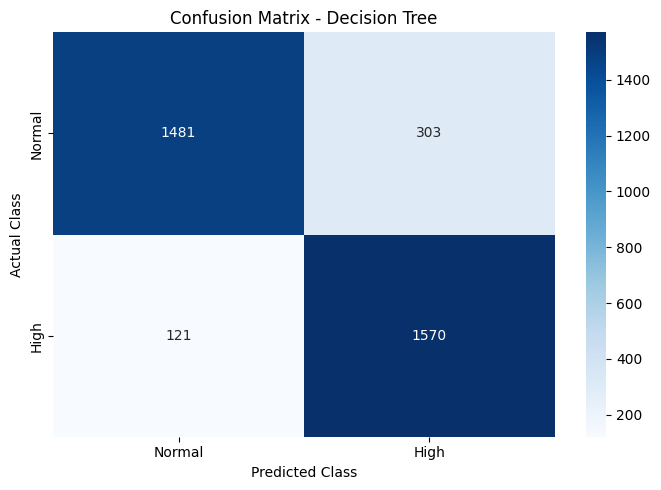

In [27]:
if best_model == 'Decision Tree':
    best_predictions = y_pred_dt
elif best_model == 'Gaussian Naive Bayes':
    best_predictions = y_pred_nb
else:
    best_predictions = y_pred_knn

cm = confusion_matrix(y_test_clf,best_predictions,labels=[0, 1])
plt.figure(figsize=(7, 5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Normal', 'High'],yticklabels=['Normal', 'High'])
plt.title("Confusion Matrix - " + best_model)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

**Classification Conclusion**

Precision measures how often a High Demand prediction is correct. Recall measures how many actual High Demand hours are identified. F1-score balances precision and recall, making it useful when the classes are imbalanced.

---
## Summary of Results

### Model Performance Summary

| Task | Models Compared | Selection Metric |
| :--- | :--- | :--- |
| **Regression** | Multiple Linear Regression; Decision Tree Regression; Polynomial Regression (degree 2) | Lowest test RMSE |
| **Classification** | KNN; Decision Tree Classifier; Gaussian Naive Bayes | Highest test F1-score |
